# PORTAFOLIO CON ACTIVOS INDEPENDIENTES VS. CORRELACIONADOS

### Preparando las herramientas (Librerías)
Para empezar, cargamos las librerías de siempre: numpy y pandas para hacer cuentas con matrices y tablas de datos, matplotlib para armar las gráficas de cómo nos fue, y yfinance para bajar los precios reales directo de Yahoo Finance.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf


---
## PARTE A: ACTIVOS DE SECTORES DISTINTOS + TIPO DE CAMBIO (USDMXN=X)

### 1. Bajando los datos y pasando todo a pesos
Aquí descargamos el historial de precios diarios de los últimos 3 años de cuatro empresas de sectores súper distintos: Nvidia (NVDA), Bimbo (BIMBOA.MX), Cemex (CEMEXCPO.MX) y AstraZeneca (AZN), además del tipo de cambio dólar-peso (USDMXN=X).

Juntamos todo en una sola tabla cuidando que las fechas cuadren (quitando días vacíos con dropna) y respetando el orden exacto de la lista para no revolver los pesos del portafolio más adelante. Como Nvidia y AstraZeneca cotizan en dólares y las mexicanas en pesos, multiplicamos el precio inicial de las gringas por el tipo de cambio actual para que todo nuestro portafolio arranque hablando el mismo idioma: pesos mexicanos.
$$\text{MXN} = \text{USD} \times \text{Tipo de Cambio (USDMXN)}$$

In [3]:
tickers = ['NVDA', 'BIMBOA.MX', 'CEMEXCPO.MX', 'AZN']
precios = yf.download(tickers, period='3Y', interval='1d', progress=False)['Close']
fx = yf.download('USDMXN=X', period='3Y', interval='1d', progress=False)['Close']

# Unimos las 4 acciones y el tipo de cambio en un solo DataFrame en el orden exacto
df_A = precios[tickers].join(fx).dropna()
rend_A = np.log(df_A).diff().dropna()

# Parámetros anualizados (252 días hábiles)
mus_A = rend_A.mean().values * 252
sigmas_A = rend_A.std().values * np.sqrt(252)
S0_orig = df_A.iloc[-1].values  # [NVDA_usd, BIMBO_mxn, CEMEX_mxn, AZN_usd, USDMXN]

# Precios iniciales estandarizados a MXN
fx_0 = S0_orig[4]
S0_mxn = np.array([
    S0_orig[0] * fx_0,  
    S0_orig[1],        
    S0_orig[2],        
    S0_orig[3] * fx_0   
])

print("Precios iniciales en MXN:", dict(zip(tickers, np.round(S0_mxn, 2))))
print("Volatilidades anualizadas:", dict(zip(df_A.columns, np.round(sigmas_A, 4))))

Precios iniciales en MXN: {'NVDA': np.float64(3231.24), 'BIMBOA.MX': np.float64(71.31), 'CEMEXCPO.MX': np.float64(19.92), 'AZN': np.float64(3449.78)}
Volatilidades anualizadas: {'NVDA': np.float64(0.4786), 'BIMBOA.MX': np.float64(0.3), 'CEMEXCPO.MX': np.float64(0.33), 'AZN': np.float64(0.2526), 'USDMXN=X': np.float64(0.1107)}


### 2. Matriz de correlación (5 factores) y el truco de Cholesky
En esta celda armamos la matriz de correlación de 5x5 (las 4 acciones más el tipo de cambio) para ver qué tanto se mueven juntos en la vida real. Luego lanzamos 10,000 simulaciones a un año de dos formas distintas:
1. Asumiendo que cada activo anda por su cuenta (choques normales independientes).
2. Conectando los movimientos reales entre activos y dólar mediante la descomposición de Cholesky ($L L^\top = \Sigma$).

Al final de cada simulación a 1 año, volvemos a convertir a pesos los precios simulados de Nvidia y AstraZeneca multiplicándolos por el tipo de cambio simulado en ese mismo escenario.

In [10]:
corr_A = rend_A.corr()
display(corr_A)

M = 10_000
np.random.seed(42)

# 1) Choques normales independientes (5 factores: 4 acciones + FX)
eps_A = np.random.normal(0, 1, (5, M))

# 2) Choques normales correlacionados con Cholesky
L_A = np.linalg.cholesky(corr_A.values)
Z_A_corr = np.dot(L_A, eps_A)

def simular_precios_A(Z_matrix):
    # Movimiento Browniano Geométrico a T = 1 año en moneda original
    ST = S0_orig[:, None] * np.exp((mus_A[:, None] - 0.5 * sigmas_A[:, None]**2) + sigmas_A[:, None] * Z_matrix)
    
    # Convertimos únicamente NVDA (0) y AZN (3) a MXN usando el FX simulado (4)
    ST_mxn = np.array([
        ST[0] * ST[4],  # NVDA en MXN
        ST[1],          # BIMBO en MXN
        ST[2],          # CEMEX en MXN
        ST[3] * ST[4]   # AZN en MXN
    ])
    return ST_mxn

ST_A_indep = simular_precios_A(eps_A)
ST_A_corr = simular_precios_A(Z_A_corr)

Ticker,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN,USDMXN=X
Ticker,,,,,
NVDA,1.000000,0.073648,0.213671,0.015498,0.024452
BIMBOA.MX,0.073648,1.000000,0.189595,0.097981,0.046222
CEMEXCPO.MX,0.213671,0.189595,1.000000,0.101119,-0.023213
AZN,0.015498,0.097981,0.101119,1.000000,0.004804
USDMXN=X,0.024452,0.046222,-0.023213,0.004804,1.000000


### 3. Poniendo a competir los portafolios: Independiente vs. Correlacionado
Ahora sí, metemos 100,000 pesos en tres combinaciones distintas:
- Caso 1: [1, 0, 0, 0] (Todo a Nvidia)
- Caso 2: [0.25, 0.25, 0.25, 0.25] (Partes iguales entre las 4 acciones)
- Caso 3: [0.1, 0.2, 0.3, 0.4] (Escalonado)

Para cada caso calculamos cuántas acciones nos alcanza a comprar hoy, cuánto valdría el portafolio en un año bajo los dos mundos (independiente vs. correlacionado) y sacamos su promedio, su volatilidad (Std) y sus métricas de susto en el 5% de los peores escenarios (VaR y CVaR al 95%). También encimamos los dos histogramas para ver la diferencia a simple vista.

=== Caso 1: [1, 0, 0, 0] (100% NVDA) ===
Independiente  -> Media: $158,605.62 | Std: $83,084.38 | VaR 95%: $-36,888.75 | CVaR 95%: $-48,071.99
Correlacionado -> Media: $158,817.87 | Std: $83,676.29 | VaR 95%: $-37,023.53 | CVaR 95%: $-48,330.07



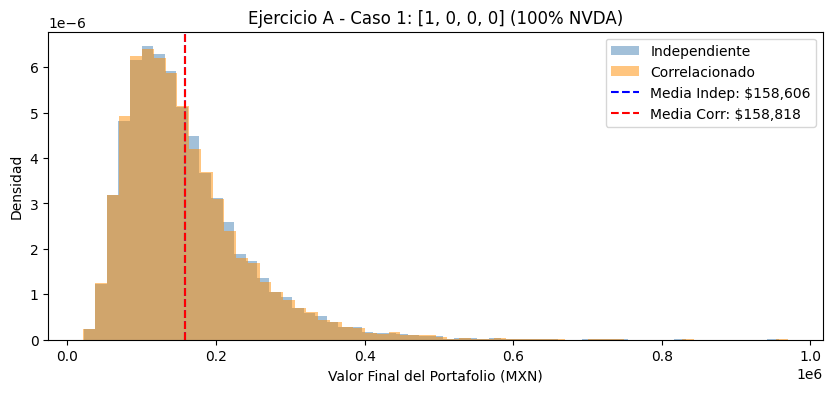

=== Caso 2: [0.25, 0.25, 0.25, 0.25] (Equitativo) ===
Independiente  -> Media: $123,471.37 | Std: $26,334.73 | VaR 95%: $-12,980.61 | CVaR 95%: $-19,348.78
Correlacionado -> Media: $123,590.91 | Std: $29,459.33 | VaR 95%: $-16,756.06 | CVaR 95%: $-23,804.40



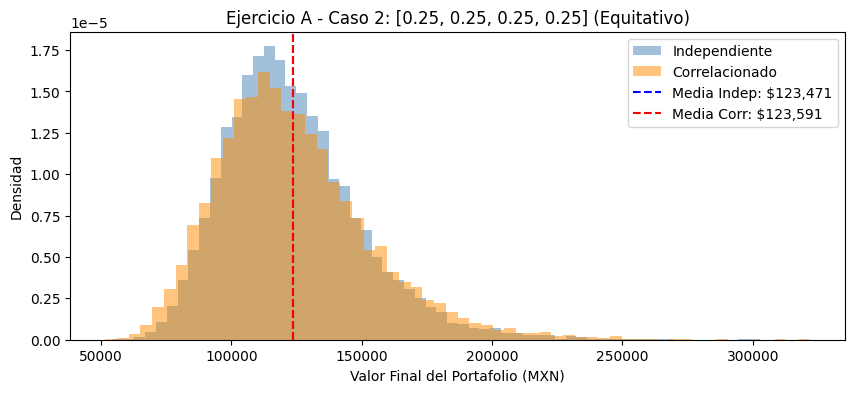

=== Caso 3: [0.1, 0.2, 0.3, 0.4] (Escalonado) ===
Independiente  -> Media: $118,431.89 | Std: $21,273.82 | VaR 95%: $-13,078.30 | CVaR 95%: $-19,222.28
Correlacionado -> Media: $118,538.80 | Std: $24,047.93 | VaR 95%: $-16,726.09 | CVaR 95%: $-23,187.65



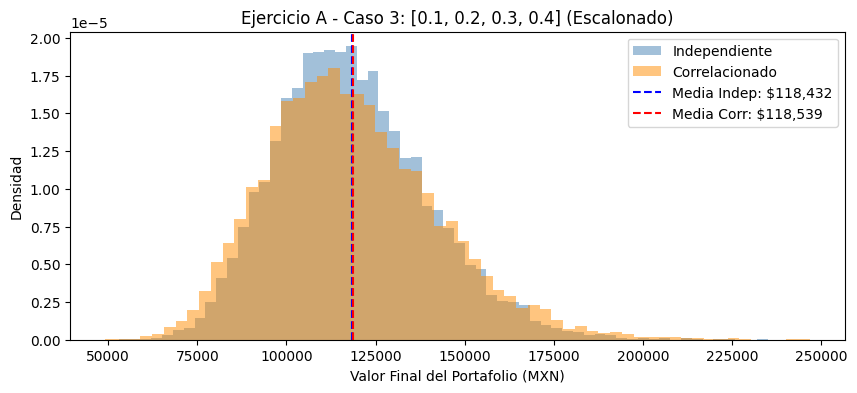

In [5]:
portafolios_A = {
    'Caso 1: [1, 0, 0, 0] (100% NVDA)': [1.0, 0.0, 0.0, 0.0],
    'Caso 2: [0.25, 0.25, 0.25, 0.25] (Equitativo)': [0.25, 0.25, 0.25, 0.25],
    'Caso 3: [0.1, 0.2, 0.3, 0.4] (Escalonado)': [0.1, 0.2, 0.3, 0.4],
}

Vo = 100_000

for nombre, w in portafolios_A.items():
    w = np.array(w)
    num_acciones = (w * Vo) / S0_mxn
    
    val_indep = np.dot(num_acciones, ST_A_indep)
    val_corr = np.dot(num_acciones, ST_A_corr)
    
    pnl_indep = val_indep - Vo
    pnl_corr = val_corr - Vo
    
    var_i = np.percentile(pnl_indep, 5)
    var_c = np.percentile(pnl_corr, 5)
    cvar_i = pnl_indep[pnl_indep <= var_i].mean()
    cvar_c = pnl_corr[pnl_corr <= var_c].mean()
    
    print(f"=== {nombre} ===")
    print(f"Independiente  -> Media: ${val_indep.mean():,.2f} | Std: ${val_indep.std():,.2f} | VaR 95%: ${var_i:,.2f} | CVaR 95%: ${cvar_i:,.2f}")
    print(f"Correlacionado -> Media: ${val_corr.mean():,.2f} | Std: ${val_corr.std():,.2f} | VaR 95%: ${var_c:,.2f} | CVaR 95%: ${cvar_c:,.2f}\n")
    
    plt.figure(figsize=(10, 4))
    plt.hist(val_indep, bins=60, density=True, alpha=0.5, color='steelblue', label='Independiente')
    plt.hist(val_corr, bins=60, density=True, alpha=0.5, color='darkorange', label='Correlacionado')
    plt.axvline(val_indep.mean(), color='blue', linestyle='--', label=f'Media Indep: ${val_indep.mean():,.0f}')
    plt.axvline(val_corr.mean(), color='red', linestyle='--', label=f'Media Corr: ${val_corr.mean():,.0f}')
    plt.title(f'Ejercicio A - {nombre}')
    plt.xlabel('Valor Final del Portafolio (MXN)')
    plt.ylabel('Densidad')
    plt.legend()
    plt.show()

### ¿Qué observamos en el Ejercicio A?
1. El efecto del dólar en el Caso 1 ([1, 0, 0, 0]): Aunque aquí metimos el 100% del dinero en una sola acción (NVDA), en realidad estamos jugando con dos variables: el precio de Nvidia en dólares y el tipo de cambio peso-dólar. En la vida real suele haber una correlación negativa entre la bolsa de EE. UU. y el peso mexicano (cuando el mercado se asusta y caen las acciones, el dólar suele subir). Eso funciona como un pequeño amortiguador natural al pasar el portafolio a pesos, haciendo que la distribución correlacionada cambie ligeramente frente a la independiente.
2. Falsa independencia entre sectores distintos (Casos 2 y 3): Aunque tecnología, panificación, cemento y farmacéutica suenen a mundos aparte, en el mercado global nada es 100% independiente; a todos les pegan las crisis globales y el movimiento del dólar. Al meter la matriz de correlaciones, cambia el ancho de la campana (la desviación estándar) y también se mueven las pérdidas extremas (VaR y CVaR).
3. El promedio casi ni se inmuta: El valor esperado (la media) sale prácticamente igual con o sin correlación; donde de verdad importa meter Cholesky es para medir bien el riesgo y no llevarnos sorpresas en las colas de pérdida.

---
## PARTE B: ACTIVOS DEL MISMO SECTOR (AAPL, MSFT, NVDA)

### 1. Descargando a las gigantes tecnológicas
Ahora nos vamos al otro extremo: armar un portafolio con puras empresas del mismo sector. Bajamos los precios diarios del último año para Apple (AAPL), Microsoft (MSFT) y Nvidia (NVDA) exactamente en ese orden. Sacamos sus rendimientos logarítmicos diarios, anualizamos su promedio y volatilidad, y revisamos su matriz de correlación para confirmar qué tan amarradas están.

In [6]:
tickers_B = ['AAPL', 'MSFT', 'NVDA']
prices_B = yf.download(tickers_B, period='1Y', interval='1d', progress=False)['Close'][tickers_B].dropna()
rend_B = np.log(prices_B).diff().dropna()

mus_B = rend_B.mean().values * 252
sigmas_B = rend_B.std().values * np.sqrt(252)
S0_B = prices_B.iloc[-1].values

corr_B = rend_B.corr()
print("Matriz de correlación (AAPL, MSFT, NVDA):")
display(corr_B)

Matriz de correlación (AAPL, MSFT, NVDA):


Ticker,AAPL,MSFT,NVDA
Ticker,,,
AAPL,1.000000,0.155491,0.059994
MSFT,0.155491,1.000000,0.233442
NVDA,0.059994,0.233442,1.000000


### 2. Simulación Monte Carlo: Independiente vs. Correlacionado (Cholesky)
Igual que arriba, corremos 10,000 escenarios posibles para dentro de un año ($T = 1$) usando la fórmula del Movimiento Browniano Geométrico:
$$S_{T,i} = S_{0,i} \exp\left(\left(\mu_i - \frac{\sigma_i^2}{2}\right)T + \sigma_i\sqrt{T}Z_i\right)$$
Primero lo hacemos con ruido totalmente independiente y luego pasándole la brocha de Cholesky para que las caídas y subidas respeten la correlación histórica entre las tres tecnológicas.

In [7]:
M = 10_000
np.random.seed(42)

# Ruido independiente
eps_B = np.random.normal(0, 1, (3, M))

# Ruido correlacionado con Cholesky
L_B = np.linalg.cholesky(corr_B.values)
Z_B_corr = np.dot(L_B, eps_B)

ST_B_indep = S0_B[:, None] * np.exp((mus_B[:, None] - 0.5 * sigmas_B[:, None]**2) + sigmas_B[:, None] * eps_B)
ST_B_corr = S0_B[:, None] * np.exp((mus_B[:, None] - 0.5 * sigmas_B[:, None]**2) + sigmas_B[:, None] * Z_B_corr)

### 3. Evaluando los 100,000 pesos en los tres esquemas y graficando
Ponemos a prueba nuestros 100,000 pesos repartidos en el orden [AAPL, MSFT, NVDA] bajo tres recetas:
- Esquema 1: [1, 0, 0] (100% en Apple)
- Esquema 2: [0.33, 0.33, 0.34] (Repartido en partes casi iguales)
- Esquema 3: [0.2, 0.2, 0.6] (Cargado fuerte hacia Nvidia)

De nuevo imprimimos media, desviación estándar, VaR y CVaR al 95% y dibujamos las campanas encimadas para comparar qué pasa cuando ignoras la correlación en un mismo sector.

=== Esquema 1: [1, 0, 0] (100% AAPL) ===
Independiente  -> Media: $130,633.99 | Std: $33,370.14 | VaR 95%: $-16,320.09 | CVaR 95%: $-24,362.80
Correlacionado -> Media: $130,633.99 | Std: $33,370.14 | VaR 95%: $-16,320.09 | CVaR 95%: $-24,362.80



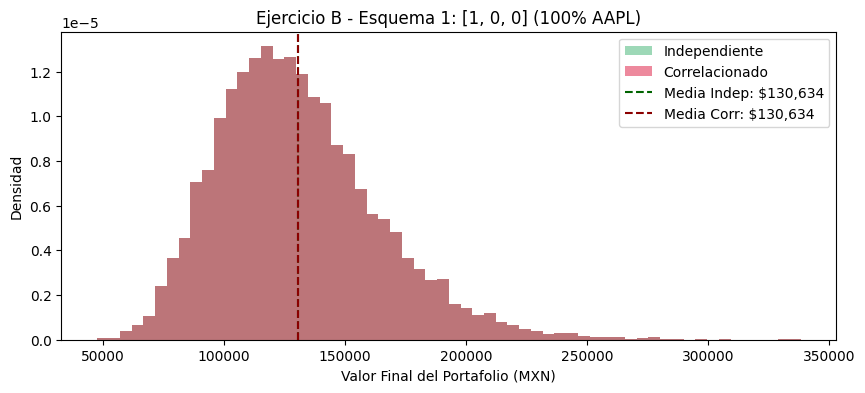

=== Esquema 2: [0.33, 0.33, 0.34] (Equitativo) ===
Independiente  -> Media: $107,536.81 | Std: $20,475.92 | VaR 95%: $-22,308.87 | CVaR 95%: $-27,955.03
Correlacionado -> Media: $107,602.34 | Std: $23,252.73 | VaR 95%: $-25,554.39 | CVaR 95%: $-31,793.89



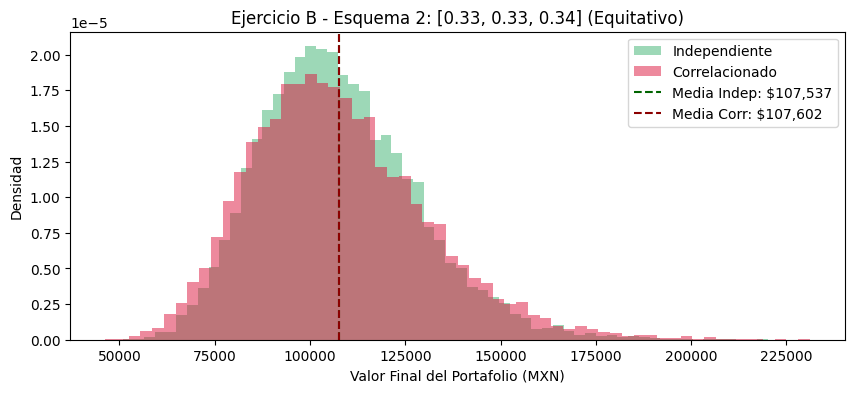

=== Esquema 3: [0.2, 0.2, 0.6] (60% NVDA) ===
Independiente  -> Media: $100,327.04 | Std: $23,721.02 | VaR 95%: $-31,952.25 | CVaR 95%: $-37,301.69
Correlacionado -> Media: $100,454.71 | Std: $25,926.02 | VaR 95%: $-35,049.87 | CVaR 95%: $-40,475.40



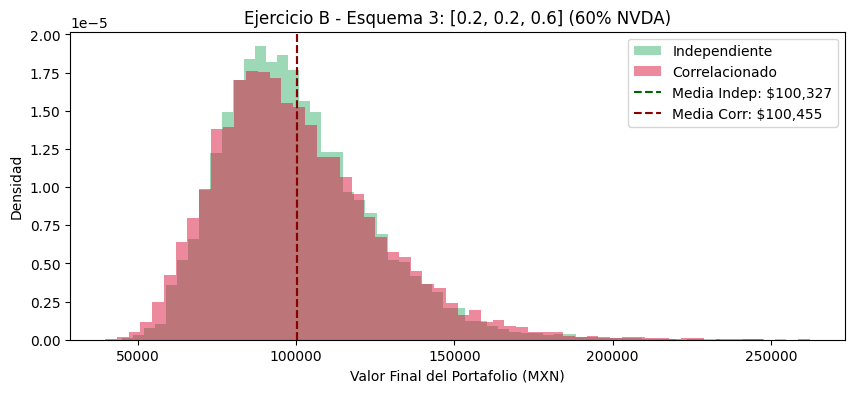

In [8]:
esquemas_B = {
    'Esquema 1: [1, 0, 0] (100% AAPL)': [1.0, 0.0, 0.0],
    'Esquema 2: [0.33, 0.33, 0.34] (Equitativo)': [0.33, 0.33, 0.34],
    'Esquema 3: [0.2, 0.2, 0.6] (60% NVDA)': [0.2, 0.2, 0.6]
}

Vo = 100_000

for nombre, w in esquemas_B.items():
    w = np.array(w)
    val_indep = Vo * np.dot(w, ST_B_indep / S0_B[:, None])
    val_corr = Vo * np.dot(w, ST_B_corr / S0_B[:, None])
    
    pnl_indep = val_indep - Vo
    pnl_corr = val_corr - Vo
    
    var_i = np.percentile(pnl_indep, 5)
    var_c = np.percentile(pnl_corr, 5)
    cvar_i = pnl_indep[pnl_indep <= var_i].mean()
    cvar_c = pnl_corr[pnl_corr <= var_c].mean()
    
    print(f"=== {nombre} ===")
    print(f"Independiente  -> Media: ${val_indep.mean():,.2f} | Std: ${val_indep.std():,.2f} | VaR 95%: ${var_i:,.2f} | CVaR 95%: ${cvar_i:,.2f}")
    print(f"Correlacionado -> Media: ${val_corr.mean():,.2f} | Std: ${val_corr.std():,.2f} | VaR 95%: ${var_c:,.2f} | CVaR 95%: ${cvar_c:,.2f}\n")
    
    plt.figure(figsize=(10, 4))
    plt.hist(val_indep, bins=60, density=True, alpha=0.5, color='mediumseagreen', label='Independiente')
    plt.hist(val_corr, bins=60, density=True, alpha=0.5, color='crimson', label='Correlacionado')
    plt.axvline(val_indep.mean(), color='darkgreen', linestyle='--', label=f'Media Indep: ${val_indep.mean():,.0f}')
    plt.axvline(val_corr.mean(), color='darkred', linestyle='--', label=f'Media Corr: ${val_corr.mean():,.0f}')
    plt.title(f'Ejercicio B - {nombre}')
    plt.xlabel('Valor Final del Portafolio (MXN)')
    plt.ylabel('Densidad')
    plt.legend()
    plt.show()

### ¿Qué observamos en el Ejercicio B?
1. Esquema 1 ([1, 0, 0] - 100% AAPL): Aquí los dos histogramas y todas las métricas salen idénticos porque todo el dinero está en un solo activo (Apple) y no hay conversión de moneda, así que lo que hagan Microsoft o Nvidia tiene peso cero y la correlación con ellas no pinta para nada.
2. Esquemas 2 ([0.33, 0.33, 0.34]) y 3 ([0.2, 0.2, 0.6]): Como las tres empresas son del sector tecnológico, se mueven en manada (tienen correlación positiva alta). Cuando metemos esa correlación en la simulación, la campana roja se hace mucho más ancha (mayor desviación estándar) y la cola izquierda se estira hacia pérdidas bastante más feas (peor VaR y peor CVaR al 95%) que en la simulación independiente.
3. Conclusión sobre la diversificación: Suponer que tus activos son independientes cuando todos vienen del mismo sector te da una falsa sensación de seguridad. El modelo independiente cree que si Apple cae, tal vez Nvidia o Microsoft suban y te salven; pero el modelo correlacionado te muestra la realidad: cuando al sector tech le da gripa, todas se caen al mismo tiempo y el golpe en los peores escenarios (VaR y CVaR) es mucho más duro.